# Building and Training SNNs from Scratch
Foundational tutorial exploring spiking neural networks (SNNs) through a custom PyTorch implementation. Built integrate-and-fire neurons, spike encoding, and surrogate gradient-based training for MNIST classification. Adapted from Ramashish Gaurav's tutorial, *Building and Training Spiking Neural Networks From Scratch*. [Gaurav's Tutorial](https://r-gaurav.github.io/2024/01/04/Building-And-Training-Spiking-Neural-Networks-From-Scratch.html)

In [1]:
class IF_neuron(object):
  def __init__(self, v_thr=1.0):
    """
    Args:
      v_thr <int>: Threshold voltage of the IF neuron, default 1.0 .
    """
    self._v_thr = v_thr
    self._v = 0

  def encode_input_and_spike(self, inp):
    """
    Integrates the input and produces a spike if the IF neuron's voltage reaches 
    or crosses threshold.
    
    Args:
      inp <float>: Scalar input to the IF neuron.
    """
    self._v = self._v + inp
    if self._v >= self._v_thr:
      self._v = 0 # Reset the voltage and produce a spike.
      return 1.0 # Spike.
    elif self._v < 0: # Rectify the voltage if it is negative.
      self._v = 0 

    return 0 # No spike.

In [3]:
# Import necessary libraries.
import numpy as np
import matplotlib.pyplot as plt
from nengo_extras.plot_spikes import plot_spikes

2026-05-09 19:53:59.340814: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
# Create one spiking neuron and encode a random input signal.
if_neuron = IF_neuron(v_thr=1) # Instantiate a neuron.
T = 100 # Set the duration of input signal in time-steps.
inp_signal = 2*(0.5 - np.random.rand(T)) # Generate signal.

spikes = []
for t in range(T): # Execute the IF neuron for the entire duration of the input.
  spikes.append(if_neuron.encode_input_and_spike(inp_signal[t]))
spikes = np.array(spikes).reshape(-1, 1)

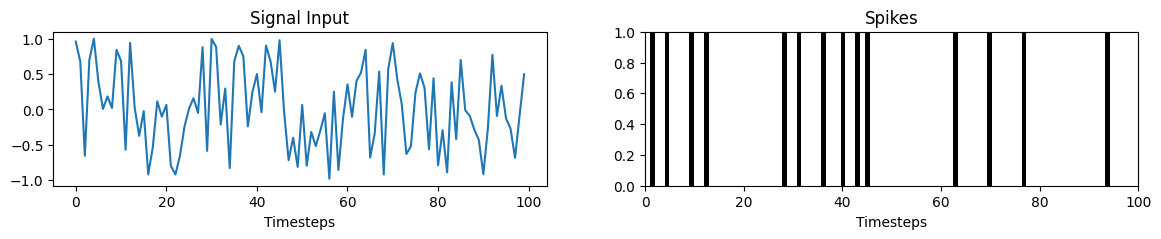

In [5]:
plt.figure(figsize=(14, 2))
plt.subplot(1, 2, 1)
plt.plot(inp_signal)
plt.title("Signal Input")
plt.xlabel("Timesteps");
plt.subplot(1, 2, 2)
plt.title("Spikes")
plot_spikes(np.arange(0, T), spikes)
plt.xlabel("Timesteps");
plt.xlim([0, 100]);

In [ ]:
import torch
from abc import abstractmethod
import numpy as np
import torchvision

V_THR = 1.0
DEVICE = "cpu" # Change it to "cuda:0" if you have an NVIDIA-GPU.
BATCH_SIZE = 500 # Change it to suit your memory availability.
TAU_CUR = 1e-3 # Time constant of current decay.

In [7]:
class BaseSpkNeuron(object):
  def __init__(self, n_neurons):
    """
    Args:
      n_neurons: Number of spiking neurons.
      v_thr <int>: Threshold voltage.
    """
    self._v = torch.zeros(BATCH_SIZE, n_neurons, device=DEVICE)
    self._v_thr = torch.as_tensor(V_THR)

  def update_voltage(self, c):
    """
    Args:
      c <float>: Current input to update the voltage.
    """
    self._v = self._v + c
    mask = self._v < 0 # Mask to rectify the voltage if negative.
    self._v[mask] = 0

  def re_initialize_voltage(self):
    """
    Resets all the neurons' voltage to zero.
    """
    self._v = torch.zeros_like(self._v)

  def reset_voltage(self, spikes):
    """
    Reset the voltage of the neurons which spiked to zero.
    """
    mask = spikes.detach() > 0
    self._v[mask] = 0

  @abstractmethod
  def spike_and_reset_voltage(self):
    """
    Abstract method to be mandatorily implemented for the neuron to spike and 
    reset the voltage.
    """
    raise NotImplementedError

In [8]:
class SrgtDrtvSpike(torch.autograd.Function):
  """
  This class implements the spiking function for the forward pass along with its
  surrogate-derivative in the backward pass.
  """
  scale = 5

  @staticmethod
  def forward(ctx, x):
    """
    Computes the spikes and returns it.

    Args:
      ctx: is the context object.
      x: is the input of the spiking function - Heaviside step function. The input
        to this function should be `v(t) - v_thr`, i.e. S(v(t)) = H(v(t) - v_thr).
    """
    ctx.save_for_backward(x)
    out = torch.zeros_like(x)
    out[x >= 0] = 1.0
    return out

  @staticmethod
  def backward(ctx, grad_output):
    """
    Computes the local gradient to be propagated back. Note that the local
    gradient = gradient of the forward function * grad_output. Here the forward
    function is estimated as the fast sigmoid function: x/(1+|x|), whose gradient
    is 1/((1+|x|)^2).

    Args:
      ctx: is the context object whose stored values would be used to calculate
        local gradient.
      grad_output: is the gradient output received from the previous layer.
    """
    x, = ctx.saved_tensors
    grad_input = grad_output.clone()
    local_grad = grad_output * 1.0/((1.0 + torch.abs(x)*SrgtDrtvSpike.scale)**2)
    return local_grad

spike_func = SrgtDrtvSpike.apply

In [9]:
class SpkEncoderLayer(BaseSpkNeuron):
  def __init__(self, n_neurons, gain=1.0, bias=0.0):
    """
    Args:
      n_neurons: Number of spiking neurons.
      gain <int>: Gain value of the neuron.
      bias <int>: Bias value of the neuron.
    """
    super().__init__(n_neurons)
    self._gain = gain
    self._bias = bias

  def spike_and_reset_voltage(self):
    delta_v = self._v - self._v_thr
    spikes = torch.zeros_like(delta_v)
    spikes[delta_v >= 0] = 1.0
    self.reset_voltage(spikes)

    return spikes

  def encode(self, x_t):
    J = self._gain * x_t + self._bias
    self.update_voltage(J)
    spikes = self.spike_and_reset_voltage()

    return spikes

In [ ]:
class SpkHiddenLayer(BaseSpkNeuron, torch.nn.Module):
    def __init__(self, n_prev, n_hidn, dt=1e-3, name="layer"):
        BaseSpkNeuron.__init__(self, n_hidn)
        torch.nn.Module.__init__(self)

        self.name = name

        self._c = torch.zeros(BATCH_SIZE, n_hidn, device=DEVICE)
        self._c_decay = torch.as_tensor(np.exp(-dt / TAU_CUR))
        self._fc = torch.nn.Linear(n_prev, n_hidn, bias=False)
        self._fc.weight.data = torch.empty(
            n_hidn, n_prev, device=DEVICE
        ).normal_(mean=0, std=2 / np.sqrt(n_prev))

        # -----------------------------
        # Metric tracking
        # -----------------------------
        self.reset_metrics()

    def reset_metrics(self):
        self.sg_availability_sum = 0.0
        self.spike_rate_sum = 0.0
        self.metric_count = 0

    def get_metrics(self):
        if self.metric_count == 0:
            return {
                "sg_availability": 0.0,
                "spike_rate": 0.0,
            }

        return {
            "sg_availability": self.sg_availability_sum / self.metric_count,
            "spike_rate": self.spike_rate_sum / self.metric_count,
        }

    def re_initialize_neuron_states(self):
        self.re_initialize_voltage()
        self._c = torch.zeros_like(self._c)

    def spike_and_reset_voltage(self):
        delta_v = self._v - self._v_thr

        # -----------------------------
        # Record SG availability
        # -----------------------------
        with torch.no_grad():
            sg_availability = 1.0 / (
                (1.0 + torch.abs(delta_v) * SrgtDrtvSpike.scale) ** 2
            )

            self.sg_availability_sum += sg_availability.mean().item()
            self.metric_count += 1

        spikes = spike_func(delta_v)

        # -----------------------------
        # Optional but useful: spike rate
        # -----------------------------
        with torch.no_grad():
            self.spike_rate_sum += spikes.mean().item()

        self.reset_voltage(spikes)

        return spikes

    def forward(self, x_t):
        x_t = self._fc(x_t)
        self._c = self._c_decay * self._c + x_t
        self.update_voltage(self._c)
        spikes = self.spike_and_reset_voltage()

        return spikes

In [ ]:
class SpkOutputLayer(SpkHiddenLayer):
    def __init__(self, n_prev, n_otp=10):
        super().__init__(n_prev, n_otp, name="output")

In [ ]:
class DenseSNN(torch.nn.Module):
    def __init__(self, n_ts):
        super().__init__()

        self.n_ts = n_ts

        self.enc_lyr = SpkEncoderLayer(n_neurons=784)

        self.hdn_lyrs = torch.nn.ModuleList()
        self.hdn_lyrs.append(
            SpkHiddenLayer(n_prev=784, n_hidn=1024, name="hidden_1")
        )
        self.hdn_lyrs.append(
            SpkHiddenLayer(n_prev=1024, n_hidn=512, name="hidden_2")
        )

        self.otp_lyr = SpkOutputLayer(n_prev=512, n_otp=10)

    def reset_metrics(self):
        for hdn_lyr in self.hdn_lyrs:
            hdn_lyr.reset_metrics()
        self.otp_lyr.reset_metrics()

    def get_metrics(self):
        metrics = {}

        for i, hdn_lyr in enumerate(self.hdn_lyrs):
            layer_metrics = hdn_lyr.get_metrics()
            metrics[f"hidden_{i+1}_sg_availability"] = layer_metrics["sg_availability"]
            metrics[f"hidden_{i+1}_spike_rate"] = layer_metrics["spike_rate"]

        output_metrics = self.otp_lyr.get_metrics()
        metrics["output_sg_availability"] = output_metrics["sg_availability"]
        metrics["output_spike_rate"] = output_metrics["spike_rate"]

        return metrics

    def _forward_through_time(self, x):
        all_ts_out_spks = torch.zeros(BATCH_SIZE, self.n_ts, 10)

        for t in range(self.n_ts):
            spikes = self.enc_lyr.encode(x)

            for hdn_lyr in self.hdn_lyrs:
                spikes = hdn_lyr(spikes)

            spikes = self.otp_lyr(spikes)
            all_ts_out_spks[:, t] = spikes

        return all_ts_out_spks

    def forward(self, x):
        self.enc_lyr.re_initialize_voltage()

        for hdn_lyr in self.hdn_lyrs:
            hdn_lyr.re_initialize_neuron_states()

        self.otp_lyr.re_initialize_neuron_states()

        all_ts_out_spks = self._forward_through_time(x)

        return all_ts_out_spks

In [15]:
from pathlib import Path

DATA_DIR = Path.home() / "Desktop" / "mnist_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(DATA_DIR)

/Users/briccs/Desktop/mnist_data


In [16]:
class TrainEvalDenseSNN(object):
  def __init__(self, n_ts=25, epochs=10):
    """
    Args:
      n_ts <int>: Number of time-steps to present each image for training/test.
      epochs <int>: Number of training epochs.
    """
    self.epochs = epochs
    self.loss_function = torch.nn.CrossEntropyLoss()
    self.model = DenseSNN(n_ts=n_ts).to(DEVICE) # n_ts = presentation time-steps.
    self.optimizer = torch.optim.Adam(self.model.parameters(), lr=1e-3)

    # Get the Train- and Test- Loader of the MNIST dataset.
    self.train_loader = torch.utils.data.DataLoader(
        torchvision.datasets.MNIST(root=str(DATA_DIR), train=True, download=True,
                      transform=torchvision.transforms.Compose([
    # ToTensor transform automatically converts all image pixels in range [0, 1].
                          torchvision.transforms.ToTensor()
                          ])
                      ),
        batch_size=BATCH_SIZE, shuffle=True)
    self.test_loader = torch.utils.data.DataLoader(
        torchvision.datasets.MNIST(root=str(DATA_DIR), train=False, download=True, 
                       transform=torchvision.transforms.Compose([
    # ToTensor transform automatically converts all image pixels in range [0, 1].
                           torchvision.transforms.ToTensor()
                           ])
                      ),
        batch_size=BATCH_SIZE, shuffle=True)

  def train(self, epoch):
    all_true_ys, all_pred_ys = [], []
    all_batches_loss = []
    self.model.train()
    for trn_x, trn_y in self.train_loader:
      # Each batch trn_x and trn_y is of shape (BATCH_SIZE, 1, 28, 28) and 
      # (BATCH_SIZE) respectively, where the image pixel values are between 
      # [0, 1], and the image class is a numeral between [0, 9].
      trn_x = trn_x.flatten(start_dim=1).to(DEVICE) # Flatten from dim 1 onwards.
      all_ts_out_spks = self.model(trn_x) # Output = (BATCH_SIZE, n_ts, #Classes).
      mean_spk_rate_over_ts = torch.mean(all_ts_out_spks, axis=1) # Mean over time-steps.
      # Shape of mean_spk_rate_all_ts is (BATCH_SIZE, #Classes).
      trn_preds = torch.argmax(mean_spk_rate_over_ts, axis=1) # ArgMax over classes.
      # Shape of trn_preds is (BATCH_SIZE,).
      all_true_ys.extend(trn_y.detach().numpy().tolist())
      all_pred_ys.extend(trn_preds.detach().numpy().tolist())

      # Compute Training Loss and Back-propagate.
      loss_value = self.loss_function(mean_spk_rate_over_ts, trn_y)
      all_batches_loss.append(loss_value.detach().item())
      self.optimizer.zero_grad()
      loss_value.backward()
      self.optimizer.step()
    
    trn_accuracy = np.mean(np.array(all_true_ys) == np.array(all_pred_ys))
    return trn_accuracy, np.mean(all_batches_loss)

  def eval(self, epoch):
    all_true_ys, all_pred_ys = [], []
    self.model.eval()
    with torch.no_grad():
      for tst_x, tst_y in self.test_loader:
      # Each batch tst_x and tst_y is of shape (BATCH_SIZE, 1, 28, 28) and 
      # (BATCH_SIZE) respectively, where the image pixel values are between 
      # [0, 1], and the image class is a numeral between [0, 9].
        tst_x = tst_x.flatten(start_dim=1).to(DEVICE) # Flatten from dim 1 onwards.
        all_ts_out_spks = self.model(tst_x)
        mean_spk_rate_over_ts = torch.mean(all_ts_out_spks, axis=1)
        tst_preds = torch.argmax(mean_spk_rate_over_ts, axis=1)
        all_true_ys.append(tst_y.detach().numpy().tolist())
        all_pred_ys.append(tst_preds.detach().numpy().tolist())
      
    tst_accuracy = np.mean(np.array(all_true_ys) == np.array(all_pred_ys))
    return tst_accuracy

  def train_eval(self):
    for epoch in range(1, self.epochs+1):
      _, mean_loss = self.train(epoch)
      tst_accuracy = self.eval(epoch)
      print("Epoch: %s, Training Loss: %s, Test Accuracy: %s" 
            % (epoch, mean_loss, tst_accuracy))

In [17]:
trev_model = TrainEvalDenseSNN(n_ts=25, epochs=10)
trev_model.train_eval()

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:01<00:00, 5090074.88it/s]


Extracting /Users/briccs/Desktop/mnist_data/MNIST/raw/train-images-idx3-ubyte.gz to /Users/briccs/Desktop/mnist_data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 2920198.97it/s]

Extracting /Users/briccs/Desktop/mnist_data/MNIST/raw/train-labels-idx1-ubyte.gz to /Users/briccs/Desktop/mnist_data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found




100%|██████████| 1648877/1648877 [00:00<00:00, 5199582.13it/s]


Extracting /Users/briccs/Desktop/mnist_data/MNIST/raw/t10k-images-idx3-ubyte.gz to /Users/briccs/Desktop/mnist_data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 1204738.43it/s]


Extracting /Users/briccs/Desktop/mnist_data/MNIST/raw/t10k-labels-idx1-ubyte.gz to /Users/briccs/Desktop/mnist_data/MNIST/raw

Epoch: 1, Training Loss: 1.6814312011003494, Test Accuracy: 0.8507
Epoch: 2, Training Loss: 1.5802027622858683, Test Accuracy: 0.9498
Epoch: 3, Training Loss: 1.5256227294603983, Test Accuracy: 0.9611
Epoch: 4, Training Loss: 1.5170706808567047, Test Accuracy: 0.9636
Epoch: 5, Training Loss: 1.5119839211304982, Test Accuracy: 0.9688
Epoch: 6, Training Loss: 1.5078141778707503, Test Accuracy: 0.9713
Epoch: 7, Training Loss: 1.5050922652085623, Test Accuracy: 0.9739
Epoch: 8, Training Loss: 1.503407147526741, Test Accuracy: 0.9754
Epoch: 9, Training Loss: 1.5017568777004877, Test Accuracy: 0.9755
Epoch: 10, Training Loss: 1.500288787484169, Test Accuracy: 0.9783
